In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("train.csv")


In [3]:
df.head()


,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency,Personality
0,0,0.0,No,6.0,4.0,No,15.0,5.0,Extrovert
1,1,1.0,No,7.0,3.0,No,10.0,8.0,Extrovert
2,2,6.0,Yes,1.0,0.0,NaN,3.0,0.0,Introvert
3,3,3.0,No,7.0,3.0,No,11.0,5.0,Extrovert
4,4,1.0,No,4.0,4.0,No,13.0,NaN,Extrovert


In [4]:
df.shape

(18524, 9)

In [5]:
df.columns

Index(['id', 'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance',
       'Going_outside', 'Drained_after_socializing', 'Friends_circle_size',
       'Post_frequency', 'Personality'],
      dtype='str')

In [6]:
df.info() #datatypes and missing values 

<class 'pandas.DataFrame'>
RangeIndex: 18524 entries, 0 to 18523
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         18524 non-null  int64  
 1   Time_spent_Alone           17334 non-null  float64
 2   Stage_fear                 16631 non-null  str    
 3   Social_event_attendance    17344 non-null  float64
 4   Going_outside              17058 non-null  float64
 5   Drained_after_socializing  17375 non-null  str    
 6   Friends_circle_size        17470 non-null  float64
 7   Post_frequency             17260 non-null  float64
 8   Personality                18524 non-null  str    
dtypes: float64(5), int64(1), str(3)
memory usage: 1.3 MB


In [ ]:
#several columns have fewer than 18,524 non-null values. This means they contain missing values.

In [7]:
df.describe()

,id,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
count,18524.000000,17334.000000,17344.000000,17058.000000,17470.000000,17260.000000
mean,9261.500000,3.137764,5.265106,4.044319,7.996737,4.982097
std,5347.562529,3.003786,2.753359,2.062580,4.223484,2.879139
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4630.750000,1.000000,3.000000,3.000000,5.000000,3.000000
50%,9261.500000,2.000000,5.000000,4.000000,8.000000,5.000000
75%,13892.250000,4.000000,8.000000,6.000000,12.000000,7.000000
max,18523.000000,11.000000,10.000000,7.000000,15.000000,10.000000


In [8]:
df['Personality'].value_counts() # examining the target variable

Personality
Extrovert    13699
Introvert     4825
Name: count, dtype: int64

In [ ]:
#There are more extroverts than introverts

In [9]:
df['Personality'].value_counts(normalize=True) * 100
#Percentage of missing values

Personality
Extrovert    73.95271
Introvert    26.04729
Name: proportion, dtype: float64

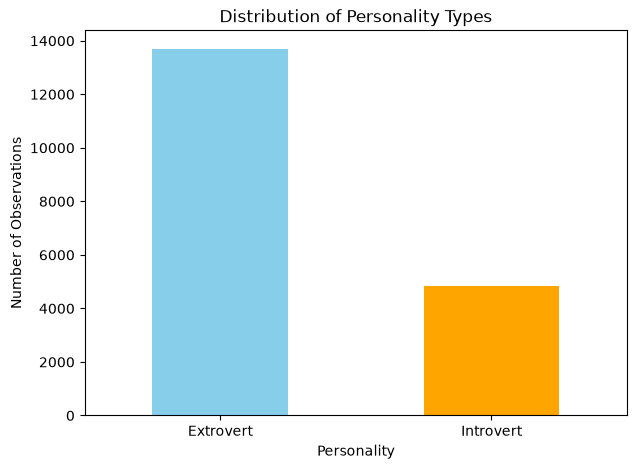

In [10]:
df['Personality'].value_counts().plot(
    kind='bar',
    figsize=(7, 5),
    color=['skyblue', 'orange']
)

plt.title('Distribution of Personality Types')
plt.xlabel('Personality')
plt.ylabel('Number of Observations')
plt.xticks(rotation=0)
plt.show()

In [12]:
#separating numerical and categorical features
numerical_features = df.select_dtypes(include=np.number).columns.tolist()

categorical_features = df.select_dtypes(include=['object', 'str']).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['id', 'Time_spent_Alone', 'Social_event_attendance', 'Going_outside', 'Friends_circle_size', 'Post_frequency']

Categorical Features:
['Stage_fear', 'Drained_after_socializing', 'Personality']


In [13]:
# Creating a missing value summary to know how many missing values each column contains
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

,Missing Values,Missing Percentage
id,0,0.00
Time_spent_Alone,1190,6.42
Stage_fear,1893,10.22
Social_event_attendance,1180,6.37
Going_outside,1466,7.91
Drained_after_socializing,1149,6.20
Friends_circle_size,1054,5.69
Post_frequency,1264,6.82
Personality,0,0.00


In [15]:
df.duplicated().sum() # no duplicates found

np.int64(0)

In [17]:
#examine the possible categories in our categorical columns.
for column in categorical_features:
    print(f"\n{column}:")
    print(df[column].value_counts())


Stage_fear:
Stage_fear
No     12609
Yes     4022
Name: count, dtype: int64

Drained_after_socializing:
Drained_after_socializing
No     13313
Yes     4062
Name: count, dtype: int64

Personality:
Personality
Extrovert    13699
Introvert     4825
Name: count, dtype: int64


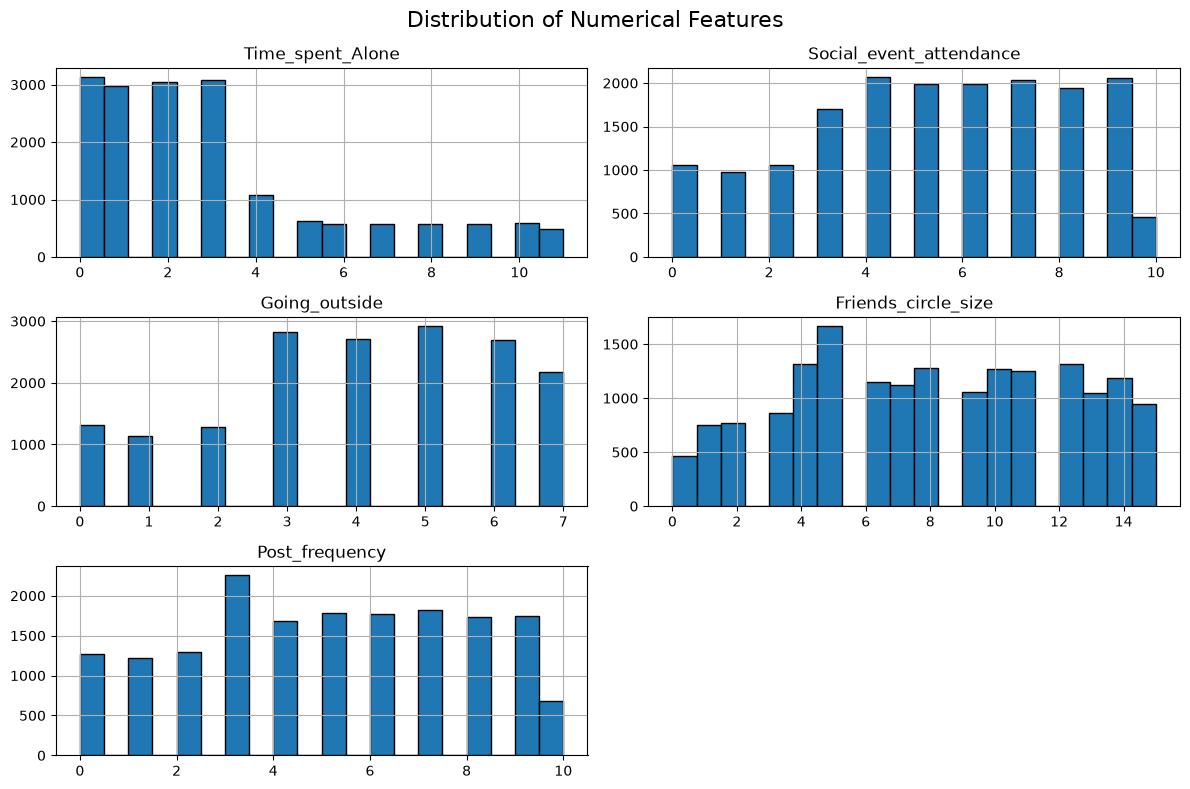

In [19]:
#examining numerical feature distribution
numerical_columns = [
    'Time_spent_Alone',
    'Social_event_attendance',
    'Going_outside',
    'Friends_circle_size',
    'Post_frequency'
]

df[numerical_columns].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

- Time_spent_Alone: Most observations are concentrated between 0 and 3.
- Social_event_attendance: Values are spread across the range, with many observations around 4–9.
- Going_outside: Many observations fall between 3 and 7.
- Friends_circle_size: Values are spread across a wider range.
- Post_frequency: Many observations fall between 3 and 9.

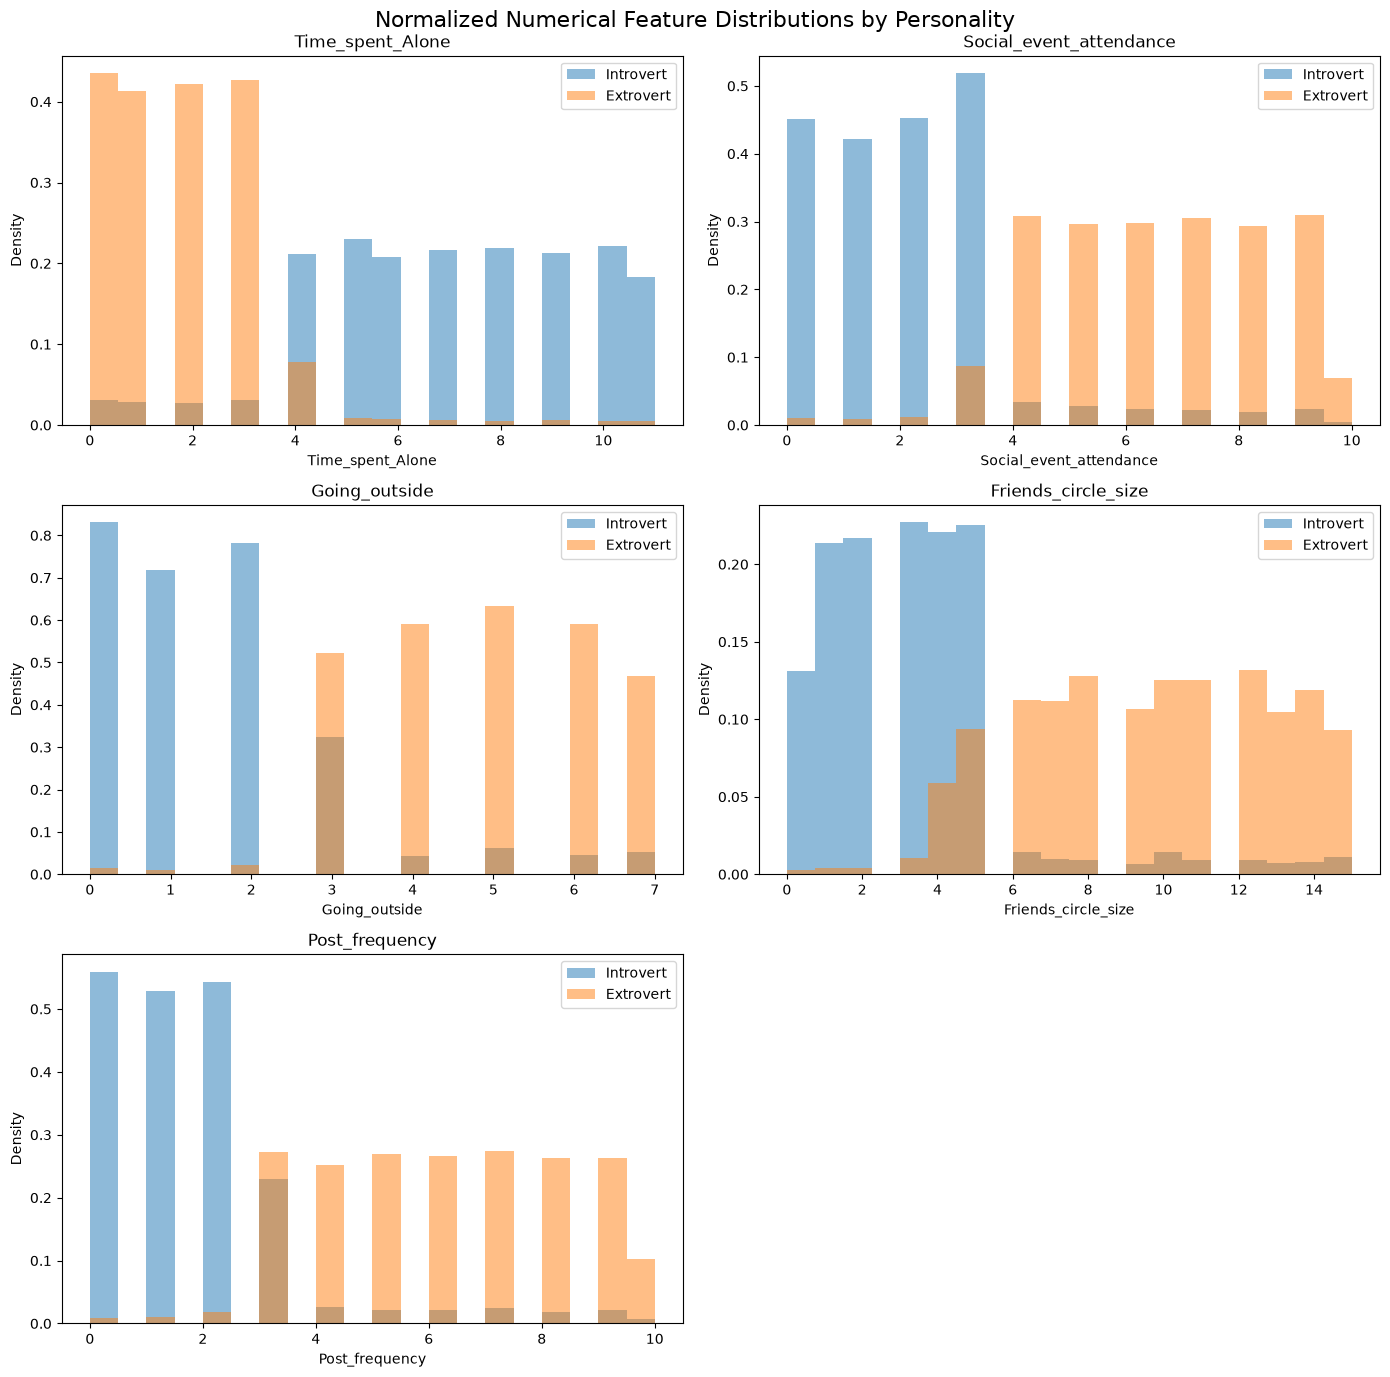

In [20]:
#comapring numerical features by personality
fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for feature, ax in zip(numerical_columns, axes.flatten()):

    # Use the same bin edges for both personality groups
    values = df[feature].dropna()
    bins = np.histogram_bin_edges(values, bins=20)

    for personality in ['Introvert', 'Extrovert']:
        data = df.loc[
            df['Personality'] == personality, feature
        ].dropna()

        ax.hist(
            data,
            bins=bins,
            density=True,
            alpha=0.5,
            label=personality
        )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel('Density')
    ax.legend()

# Hide the unused sixth plot
axes.flatten()[-1].set_visible(False)

plt.suptitle(
    'Normalized Numerical Feature Distributions by Personality',
    fontsize=16
)

plt.tight_layout()
plt.show()

- Time_spent_Alone:Introverts generally have higher values.
- Social_event_attendance: Extroverts generally have higher values.
- Going_outside:Extroverts generally have higher values.
- Friends_circle_size: Extroverts generally have larger friend circles.
- Post_frequency: Extroverts generally have higher posting frequency.

In [21]:
#Comapring categorical features by personality
categorical_columns = [
    'Stage_fear',
    'Drained_after_socializing'
]

for feature in categorical_columns:

    percentage_table = pd.crosstab(
        df['Personality'],
        df[feature],
        normalize='index'
    ) * 100

    print(f"\n{feature} (%)")
    display(percentage_table.round(2))


Stage_fear (%)


Stage_fear,No,Yes
Personality,,
Extrovert,98.12,1.88
Introvert,7.23,92.77



Drained_after_socializing (%)


Drained_after_socializing,No,Yes
Personality,,
Extrovert,98.22,1.78
Introvert,7.54,92.46


In [ ]:
#Most Introverts reported feeling drained after socializing, while most Extroverts reported not feeling drained.

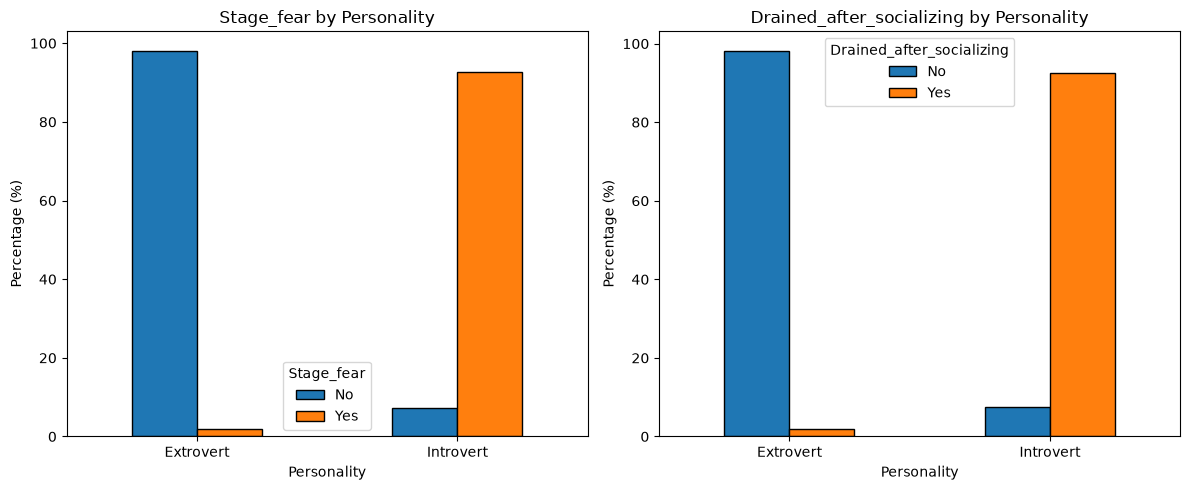

In [22]:
#Visual of the categorical features
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for feature, ax in zip(categorical_columns, axes):

    percentage_table = pd.crosstab(
        df['Personality'],
        df[feature],
        normalize='index'
    ) * 100

    percentage_table.plot(
        kind='bar',
        ax=ax,
        edgecolor='black'
    )

    ax.set_title(f'{feature} by Personality')
    ax.set_xlabel('Personality')
    ax.set_ylabel('Percentage (%)')
    ax.legend(title=feature)
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
#Preprocessing

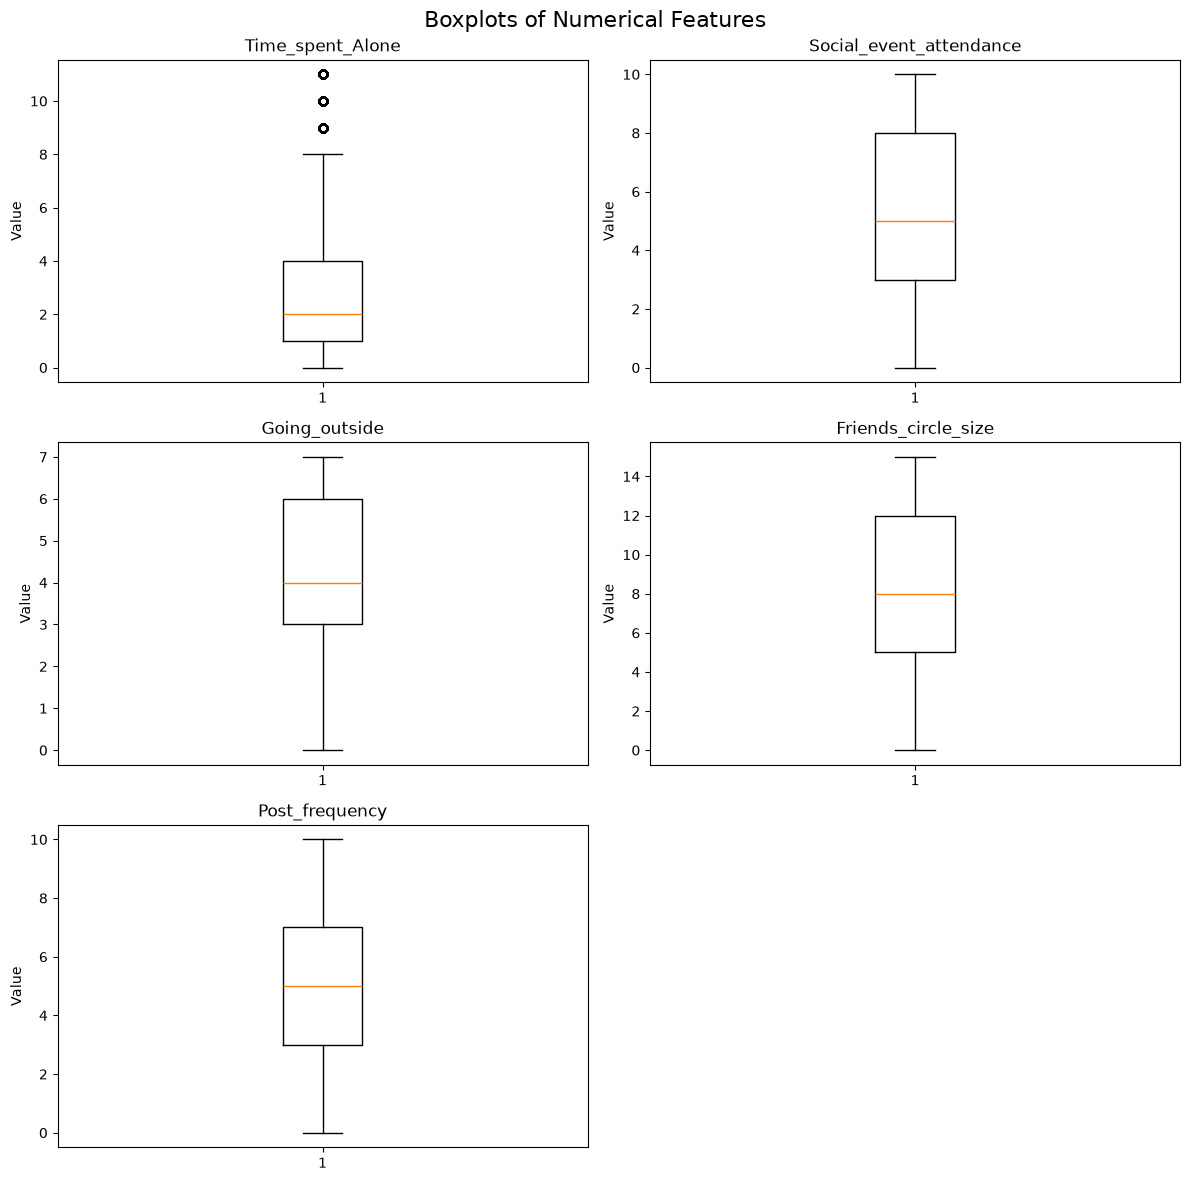

In [23]:
#checking for potential outliers
fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for feature, ax in zip(numerical_columns, axes.flatten()):
    ax.boxplot(df[feature].dropna())
    ax.set_title(feature)
    ax.set_ylabel('Value')

axes.flatten()[-1].set_visible(False)

plt.suptitle('Boxplots of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

Time_spent_Alone: few potential outliers appear above 8.
Social_event_attendance: No obvious outliers.
Going_outside: No obvious outliers.
Friends_circle_size: No obvious outliers.
Post_frequency: No obvious outliers.

In [24]:
# Checking numerical feature ranges
range_summary = pd.DataFrame({
    'Minimum': df[numerical_columns].min(),
    'Maximum': df[numerical_columns].max(),
    'Mean': df[numerical_columns].mean(),
    'Median': df[numerical_columns].median()
})

display(range_summary.round(2))

,Minimum,Maximum,Mean,Median
Time_spent_Alone,0.0,11.0,3.14,2.0
Social_event_attendance,0.0,10.0,5.27,5.0
Going_outside,0.0,7.0,4.04,4.0
Friends_circle_size,0.0,15.0,8.00,8.0
Post_frequency,0.0,10.0,4.98,5.0


- All five numerical features have a minimum of 0.
- Friends_circle_size has the largest maximum value (15).
- Time_spent_Alone has a mean of 3.14 and a median of 2, suggesting some higher values pull its average upward.
- We haven't found any clearly impossible numerical values.

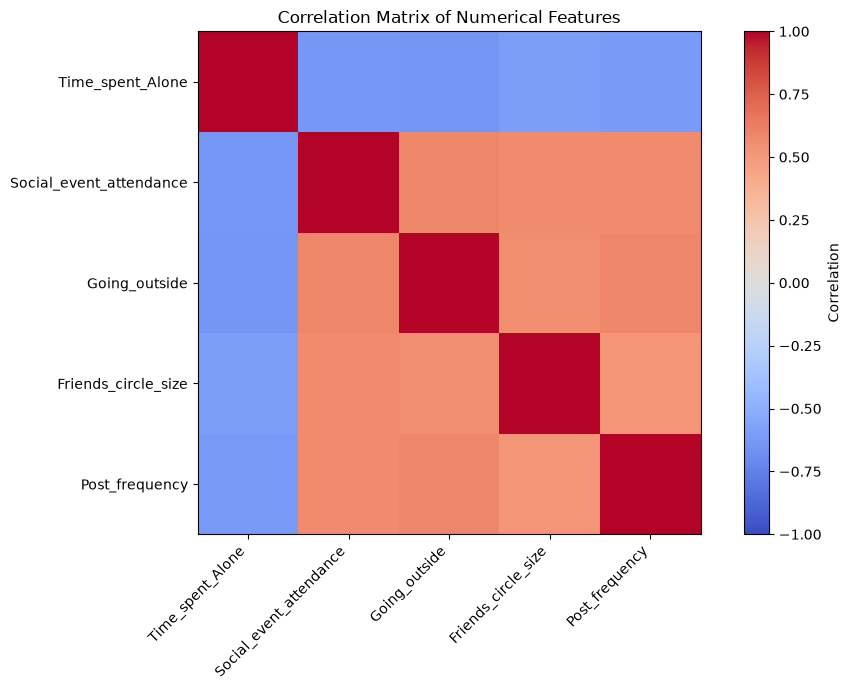

In [25]:
#Examining correlations between numerical features
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(numerical_columns)),
    numerical_columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(numerical_columns)),
    numerical_columns
)

plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

- Time_spent_Alone: Shows negative correlations with the other numerical features.
- Social_event_attendance: Shows positive correlations with Going_outside, Friends_circle_size, and Post_frequency.
- Going_outside: Shows positive correlations with Friends_circle_size and Post_frequency.
- Friends_circle_size: Shows a positive correlation with Post_frequency.
- The heatmap suggests that people who spend more time alone tend to have lower values in the other numerical features in this dataset.

In [26]:
correlation_matrix.round(2)

,Time_spent_Alone,Social_event_attendance,Going_outside,Friends_circle_size,Post_frequency
Time_spent_Alone,1.00,-0.63,-0.64,-0.60,-0.61
Social_event_attendance,-0.63,1.00,0.59,0.57,0.57
Going_outside,-0.64,0.59,1.00,0.55,0.58
Friends_circle_size,-0.60,0.57,0.55,1.00,0.52
Post_frequency,-0.61,0.57,0.58,0.52,1.00


- Time_spent_Alone has moderately strong negative correlations with the other numerical features, ranging from −0.60 to −0.64.
- Social_event_attendance has positive correlations with the other social-activity features, ranging from 0.57 to 0.59.
- Going_outside and Post_frequency have a positive correlation of 0.58.
- Friends_circle_size and Post_frequency have a positive correlation of 0.52.

In [27]:
# Loading test dataset
test_df = pd.read_csv("test.csv")

print("Test dataset shape:", test_df.shape)

display(test_df.head())

Test dataset shape: (6175, 8)


,id,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency
0,18524,3.0,No,7.0,4.0,No,6.0,NaN
1,18525,NaN,Yes,0.0,0.0,Yes,5.0,1.0
2,18526,3.0,No,5.0,6.0,No,15.0,9.0
3,18527,3.0,No,4.0,4.0,No,5.0,6.0
4,18528,9.0,Yes,1.0,2.0,Yes,1.0,1.0


- The first test ID is 18524.
- The test data also contains missing values.
- will use trained model to predict the missing Personality labels.

In [28]:
# comparing training and test columns
print("Training columns:")
print(df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nTest columns missing from training:")
print(set(test_df.columns) - set(df.columns))

print("\nTraining columns missing from test:")
print(set(df.columns) - set(test_df.columns))

Training columns:
['id', 'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency', 'Personality']

Test columns:
['id', 'Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']

Test columns missing from training:
set()

Training columns missing from test:
{'Personality'}


In [29]:
# checking missing values from test data
test_missing_summary = pd.DataFrame({
    'Missing Values': test_df.isnull().sum(),
    'Missing Percentage': (test_df.isnull().mean() * 100).round(2)
})

display(test_missing_summary)

,Missing Values,Missing Percentage
id,0,0.00
Time_spent_Alone,425,6.88
Stage_fear,598,9.68
Social_event_attendance,397,6.43
Going_outside,466,7.55
Drained_after_socializing,432,7.00
Friends_circle_size,350,5.67
Post_frequency,408,6.61


In [30]:
# Separate training features and target
X = df.drop(columns=['id', 'Personality'])
y = df['Personality']

# Separate test features
X_test = test_df.drop(columns=['id'])

# Preserve test IDs for our final Kaggle submission
test_ids = test_df['id']

print("Training features:", X.shape)
print("Target:", y.shape)
print("Test features:", X_test.shape)

Training features: (18524, 7)
Target: (18524,)
Test features: (6175, 7)


X contains the input features.
y contains the target we want to predict (Personality).
X_test contains the test features.
excluding id because it is only an identifier.

In [31]:
print("Training feature data types:")
display(X.dtypes)

Training feature data types:


Time_spent_Alone             float64
Stage_fear                       str
Social_event_attendance      float64
Going_outside                float64
Drained_after_socializing        str
Friends_circle_size          float64
Post_frequency               float64
dtype: object

In [32]:
missing_features = pd.DataFrame({
    'Missing Values': X.isnull().sum(),
    'Missing Percentage': (X.isnull().mean() * 100).round(2)
})

display(missing_features)

,Missing Values,Missing Percentage
Time_spent_Alone,1190,6.42
Stage_fear,1893,10.22
Social_event_attendance,1180,6.37
Going_outside,1466,7.91
Drained_after_socializing,1149,6.20
Friends_circle_size,1054,5.69
Post_frequency,1264,6.82


Handling missing value based in datatype

Numerical features: Use the median to fill missing values. The median is less affected by unusually high or low values.

Categorical features: Use the most frequent category (mode).

In [33]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [64]:
#Spliting training data
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2008,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

Training features: (14819, 7)
Validation features: (3705, 7)
Training target: (14819,)
Validation target: (3705,)


80% training data: Used to teach the model.
20% validation data: Used to evaluate how well the model performs on unseen data.

In [65]:
#Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(include=['object', 'str']).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Time_spent_Alone', 'Social_event_attendance', 'Going_outside', 'Friends_circle_size', 'Post_frequency']
Categorical features: ['Stage_fear', 'Drained_after_socializing']


If I were to delete the missing values
Original number of rows: 18524
Rows remaining: 10189
Rows deleted: 8335
Percentage deleted: 45.0 %

In [66]:
#create imputers
# Numerical imputer: replaces missing values with the median
numerical_imputer = SimpleImputer(strategy='median')

# Categorical imputer: replaces missing values with the most frequent value
categorical_imputer = SimpleImputer(strategy='most_frequent')

In [67]:
numerical_imputer.fit(X_train[numerical_features])

categorical_imputer.fit(X_train[categorical_features])

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Stage_fear','Drained_after_socializing']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[object](2,)","['No','No']"


In [68]:
#Applying the imputers
# Impute numerical features
X_train[numerical_features] = numerical_imputer.transform(
    X_train[numerical_features]
)

X_val[numerical_features] = numerical_imputer.transform(
    X_val[numerical_features]
)

# Impute categorical features
X_train[categorical_features] = categorical_imputer.transform(
    X_train[categorical_features]
)

X_val[categorical_features] = categorical_imputer.transform(
    X_val[categorical_features]
)

In [69]:
print("Missing values in training data:")
display(X_train.isnull().sum())

print("\nMissing values in validation data:")
display(X_val.isnull().sum())

Missing values in training data:


Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
dtype: int64


Missing values in validation data:


Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
dtype: int64

In [70]:
#Encoding categorical variables
# Convert categorical values into numerical values
encoding_map = {'No': 0, 'Yes': 1}

for feature in categorical_features:
    X_train[feature] = X_train[feature].map(encoding_map)
    X_val[feature] = X_val[feature].map(encoding_map)

display(X_train.head())

,Time_spent_Alone,Stage_fear,Social_event_attendance,Going_outside,Drained_after_socializing,Friends_circle_size,Post_frequency
142,1.0,0,7.0,4.0,0,12.0,4.0
4185,1.0,0,4.0,7.0,0,14.0,6.0
9992,2.0,0,9.0,5.0,0,14.0,5.0
2422,11.0,1,0.0,1.0,1,3.0,4.0
9509,1.0,0,8.0,4.0,0,5.0,6.0


In [71]:
#Verifying encoding
print("Stage_fear values:")
print(X_train['Stage_fear'].value_counts())

print("\nDrained_after_socializing values:")
print(X_train['Drained_after_socializing'].value_counts())

print("\nUpdated data types:")
display(X_train.dtypes)

Stage_fear values:
Stage_fear
0    11607
1     3212
Name: count, dtype: int64

Drained_after_socializing values:
Drained_after_socializing
0    11576
1     3243
Name: count, dtype: int64

Updated data types:


Time_spent_Alone             float64
Stage_fear                     int64
Social_event_attendance      float64
Going_outside                float64
Drained_after_socializing      int64
Friends_circle_size          float64
Post_frequency               float64
dtype: object

In [72]:
#Checking target variable
print("Training target distribution:")
print(y_train.value_counts())

print("\nTraining target percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

Training target distribution:
Personality
Extrovert    10959
Introvert     3860
Name: count, dtype: int64

Training target percentages:
Personality
Extrovert    73.95
Introvert    26.05
Name: proportion, dtype: float64


In [73]:
#Encoding the target variable
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

print("Personality encoding:")
print(dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))

Personality encoding:
{'Extrovert': np.int64(0), 'Introvert': np.int64(1)}


In [74]:
#Preparing the test dataset
# Separate numerical and categorical test features
X_test[numerical_features] = numerical_imputer.transform(
    X_test[numerical_features]
)

X_test[categorical_features] = categorical_imputer.transform(
    X_test[categorical_features]
)

# Encode categorical test features
for feature in categorical_features:
    X_test[feature] = X_test[feature].map(encoding_map)

print("Missing values in test data:")
display(X_test.isnull().sum())

print("\nTest data types:")
display(X_test.dtypes)

Missing values in test data:


Time_spent_Alone             0
Stage_fear                   0
Social_event_attendance      0
Going_outside                0
Drained_after_socializing    0
Friends_circle_size          0
Post_frequency               0
dtype: int64


Test data types:


Time_spent_Alone             float64
Stage_fear                     int64
Social_event_attendance      float64
Going_outside                float64
Drained_after_socializing      int64
Friends_circle_size          float64
Post_frequency               float64
dtype: object

Zero missing values.
Seven numerical features.
The same feature columns as your training and validation datasets.
The same imputation and categorical encoding rules.

In [75]:
#Verifying feature consistency
print("Training columns:")
print(X_train.columns.tolist())

print("\nValidation columns:")
print(X_val.columns.tolist())

print("\nTest columns:")
print(X_test.columns.tolist())

print("\nDo all columns match?")
print(
    list(X_train.columns) == list(X_val.columns) ==
    list(X_test.columns)
)

Training columns:
['Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']

Validation columns:
['Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']

Test columns:
['Time_spent_Alone', 'Stage_fear', 'Social_event_attendance', 'Going_outside', 'Drained_after_socializing', 'Friends_circle_size', 'Post_frequency']

Do all columns match?
True


In [47]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 12.1 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.6/206.6 MB 12.3 MB/s  0:00:16m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]
Note: you may need to restart the kernel to use updated packages.


In [76]:
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

import matplotlib.pyplot as plt

In [78]:
#Using XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=2008
)

xgb_model.fit(X_train, y_train_encoded)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [79]:
#validation predictions
y_pred = xgb_model.predict(X_val)

print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_val_encoded[:10])

First 10 predictions: [1 0 0 0 0 0 0 0 0 1]
First 10 actual values: [1 0 0 0 0 0 0 0 0 1]


0 = Extrovert
1 = Introvert

In [80]:
accuracy = accuracy_score(y_val_encoded, y_pred)

print("XGBoost Validation Accuracy:", round(accuracy * 100, 2), "%")

XGBoost Validation Accuracy: 96.84 %


In [82]:
#classification report
print(classification_report(
    y_val_encoded,
    y_pred,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

   Extrovert       0.98      0.98      0.98      2740
   Introvert       0.94      0.94      0.94       965

    accuracy                           0.97      3705
   macro avg       0.96      0.96      0.96      3705
weighted avg       0.97      0.97      0.97      3705



Extrovert: The model correctly identifies approximately 98% of actual Extroverts.
Introvert: The model correctly identifies approximately 94% of actual Introverts.
F1-score: Both classes have strong precision and recall balance.
Accuracy: 96.84% overall, rounded to 0.97 in the report.

Drained_after_socializing    0.650619
Time_spent_Alone             0.191756
Stage_fear                   0.099588
Social_event_attendance      0.034514
Going_outside                0.010446
Post_frequency               0.009878
Friends_circle_size          0.003199
dtype: float32

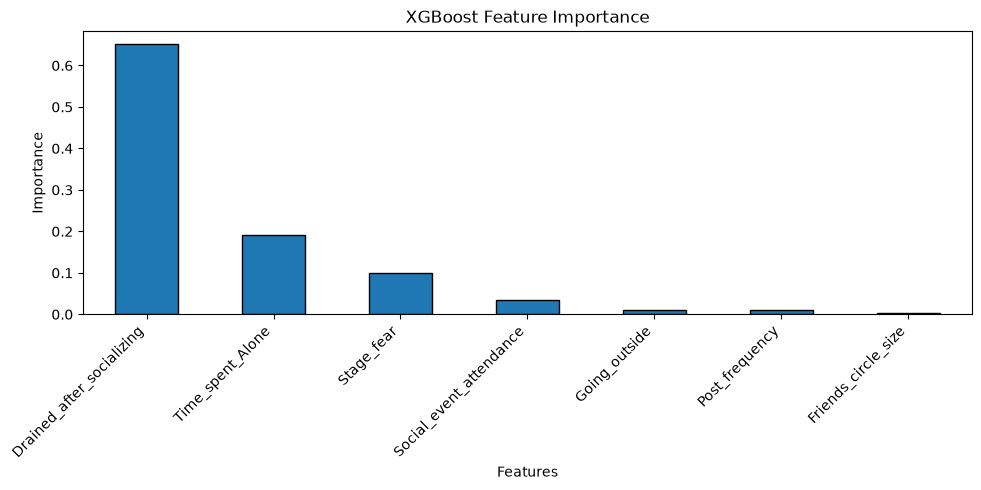

In [114]:
#Feature importance for original XGboost model
feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(feature_importance)

feature_importance.plot(
    kind='bar',
    figsize=(10, 5),
    edgecolor='black'
)

plt.title('XGBoost Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

- Drained_after_socializing is the most influential feature, accounting for approximately 65.06% of the model's total importance.
- Time_spent_Alone is second at approximately 19.18%.
- Stage_fear is third at approximately 9.96%.
The remaining four features have relatively low importance.

In [84]:
#Comparing actual and predicted values 
comparison = pd.DataFrame({
    'Actual': label_encoder.inverse_transform(y_val_encoded),
    'Predicted': label_encoder.inverse_transform(y_pred)
})

display(comparison.head(20))

,Actual,Predicted
0,Introvert,Introvert
1,Extrovert,Extrovert
2,Extrovert,Extrovert
3,Extrovert,Extrovert
4,Extrovert,Extrovert
5,Extrovert,Extrovert
6,Extrovert,Extrovert
7,Extrovert,Extrovert
8,Extrovert,Extrovert
9,Introvert,Introvert


Incorrect prediction
Row 16: Actual = Extrovert
Predicted = Introvert

In [85]:
#Creating tuned model
from sklearn.model_selection import GridSearchCV

In [86]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [2, 3, 4],
    'learning_rate': [0.05, 0.1, 0.2]
}

In [87]:
grid_search = GridSearchCV(
    estimator=XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=2008
    ),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    verbose=1
)

scoring='accuracy': Compares models using accuracy.
cv=5: Divides the training data into five folds for cross-validation.
n_jobs=-1: Uses all available CPU cores.
verbose=1: Displays progress information.

In [88]:
grid_search.fit(X_train, y_train_encoded)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.05, 0.1, ...], 'max_depth': [2, 3, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_pl

In [89]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(round(grid_search.best_score_ * 100, 2), "%")

Best Parameters:
{'learning_rate': 0.2, 'max_depth': 2, 'n_estimators': 100}

Best Cross-Validation Accuracy:
96.88 %


In [90]:
best_xgb_model = grid_search.best_estimator_

In [91]:
#Predictions with tuned model
y_pred_tuned = best_xgb_model.predict(X_val)

In [92]:
tuned_accuracy = accuracy_score(y_val_encoded, y_pred_tuned)

print("Original XGBoost Accuracy:", round(accuracy * 100, 2), "%")
print("Tuned XGBoost Accuracy:", round(tuned_accuracy * 100, 2), "%")

Original XGBoost Accuracy: 96.84 %
Tuned XGBoost Accuracy: 96.9 %


In [93]:
#Classification report fot the tuned model
print(classification_report(
    y_val_encoded,
    y_pred_tuned,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

   Extrovert       0.98      0.98      0.98      2740
   Introvert       0.94      0.94      0.94       965

    accuracy                           0.97      3705
   macro avg       0.96      0.96      0.96      3705
weighted avg       0.97      0.97      0.97      3705



The tuned model improved overall validation accuracy from 96.84% to 96.90%, while maintaining the same rounded class-level metrics.

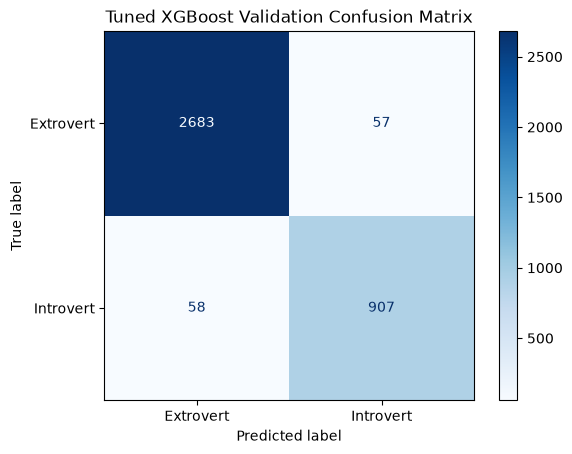

In [94]:
#Confusion matrix for tuned model
cm_tuned = confusion_matrix(y_val_encoded, y_pred_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=label_encoder.classes_
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Tuned XGBoost Validation Confusion Matrix')
plt.show()

In [99]:
best_xgb_model.fit(
    X_train,
    y_train_encoded,
    eval_set=[
        (X_train, y_train_encoded),
        (X_val, y_val_encoded)
    ],
    verbose=False
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [101]:
best_xgb_model.fit(X_train, y_train_encoded)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


Drained_after_socializing    0.830210
Stage_fear                   0.069825
Time_spent_Alone             0.068525
Social_event_attendance      0.015556
Going_outside                0.009698
Post_frequency               0.005014
Friends_circle_size          0.001172
dtype: float32

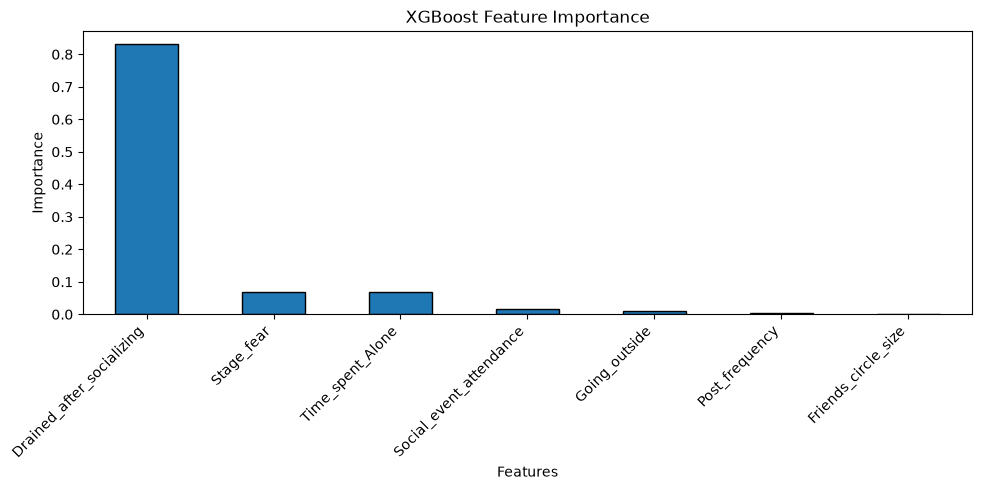

In [117]:
# Get the best XGBoost model selected by GridSearchCV
xgb_model = grid_search.best_estimator_
# Feature importance
feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(feature_importance)
# Plot feature importance
feature_importance.plot(
    kind='bar',
    figsize=(10, 5),
    edgecolor='black'
)

plt.title('XGBoost Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [115]:
# Display the model's best parameters
print(best_xgb_model.get_params())

# Display the number of boosting rounds
print(best_xgb_model.n_estimators)

# Display feature importance
print(best_xgb_model.feature_importances_)

# Display the classes learned by the model
print(best_xgb_model.classes_)

{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.2, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 2, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 100, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 2008, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}
100
[0.06852496 0.06982471 0.0155563  0.00969821 0.8302103  0.0011719
 0.005

Model parameters
- learning_rate = 0.2
- max_depth = 2
- n_estimators = 100
- objective = 'binary:logistic'
- eval_metric = 'logloss'
- random_state = 2008
- boosting rounds: 100

In [103]:
eval_results = best_xgb_model.evals_result()

print("Available evaluation sets:", eval_results.keys())

print("Training log-loss values:",
      len(eval_results['validation_0']['logloss']))

print("Validation log-loss values:",
      len(eval_results['validation_1']['logloss']))

Available evaluation sets: dict_keys(['validation_0', 'validation_1'])
Training log-loss values: 100
Validation log-loss values: 100


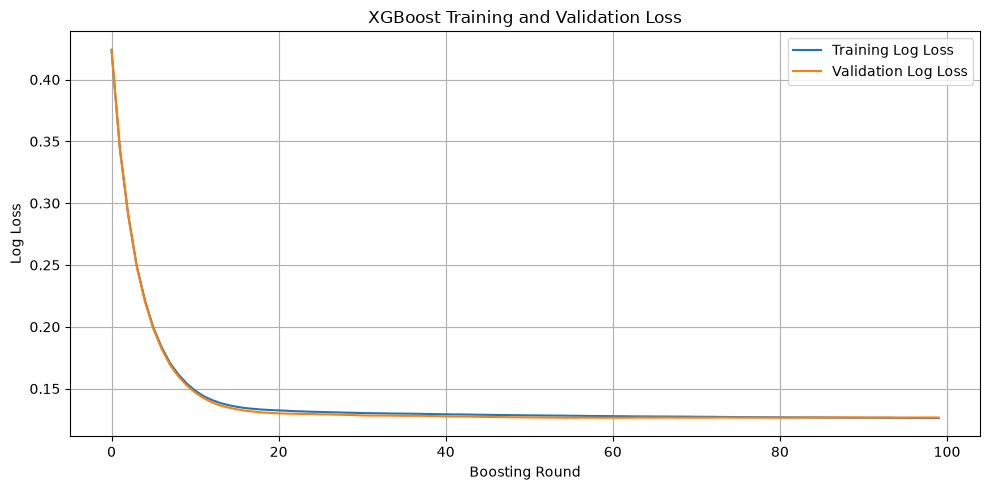

In [104]:
train_loss = eval_results['validation_0']['logloss']
val_loss = eval_results['validation_1']['logloss']

plt.figure(figsize=(10, 5))

plt.plot(train_loss, label='Training Log Loss')
plt.plot(val_loss, label='Validation Log Loss')

plt.xlabel('Boosting Round')
plt.ylabel('Log Loss')
plt.title('XGBoost Training and Validation Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [105]:
y_pred_tuned = best_xgb_model.predict(X_val)

tuned_accuracy = accuracy_score(y_val_encoded, y_pred_tuned)

print("Tuned Validation Accuracy:", tuned_accuracy)

Tuned Validation Accuracy: 0.9689608636977058


In [107]:
#Performance accuracy table
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({
    'Model': ['Original XGBoost', 'Tuned XGBoost'],
    'Accuracy': [
        accuracy_score(y_val_encoded, y_pred),
        accuracy_score(y_val_encoded, y_pred_tuned)
    ],
    'Precision': [
        precision_score(y_val_encoded, y_pred, average='weighted'),
        precision_score(y_val_encoded, y_pred_tuned, average='weighted')
    ],
    'Recall': [
        recall_score(y_val_encoded, y_pred, average='weighted'),
        recall_score(y_val_encoded, y_pred_tuned, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_val_encoded, y_pred, average='weighted'),
        f1_score(y_val_encoded, y_pred_tuned, average='weighted')
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Original XGBoost,0.968421,0.968411,0.968421,0.968416
1,Tuned XGBoost,0.968961,0.968951,0.968961,0.968956


The tuned model performed slightly better
Accuracy: Overall proportion of correct predictions.
Precision: How often positive predictions were correct.
Recall: How many actual positive cases were identified.
F1 Score: Balance between precision and recall.

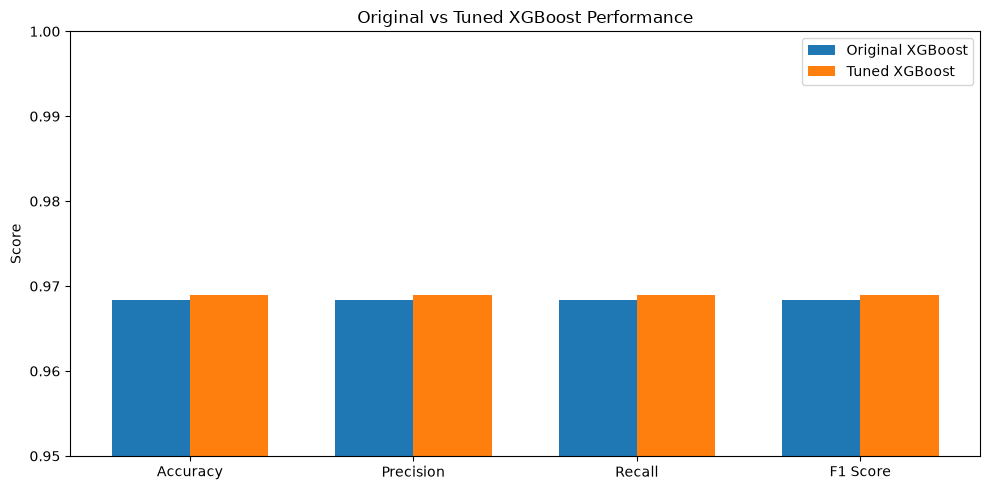

In [108]:
#comaprison visualization
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

original_scores = comparison.iloc[0, 1:].values
tuned_scores = comparison.iloc[1, 1:].values

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, original_scores, width,
        label='Original XGBoost')

plt.bar(x + width/2, tuned_scores, width,
        label='Tuned XGBoost')

plt.xticks(x, metrics)
plt.ylabel('Score')
plt.title('Original vs Tuned XGBoost Performance')
plt.ylim(0.95, 1.0)
plt.legend()
plt.tight_layout()
plt.show()

XGBoost successfully classified the personality labels.
Hyperparameter tuning slightly improved validation performance.
The tuned model achieved approximately 96.90% accuracy.
Drained_after_socializing was the most important feature in the tuned model.

In [109]:
import sys
import platform
import os
import pandas as pd
import numpy as np
import matplotlib
import sklearn
import xgboost

print("Python version:", sys.version)
print("Operating system:", platform.platform())
print("Processor:", platform.processor())
print("CPU cores:", os.cpu_count())

print("\nPackage versions:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

Python version: 3.14.4 (main, Aug 20 2026, 10:41:58) [GCC 15.2.0]
Operating system: Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.43
Processor: 
CPU cores: 16

Package versions:
Pandas: 3.1.1
NumPy: 2.5.4
Matplotlib: 3.11.2
Scikit-learn: 1.9.1
XGBoost: 3.4.1


### Software and Hardware Environment

The project was developed using Python 3.14.4 in a Jupyter Notebook environment running on Linux through Windows Subsystem for Linux 2 (WSL2).

**Hardware environment:**
- Operating system: Linux (WSL2)
- Available CPU cores: 16

**Software and library versions:**

| Software/Library | Version |
|---|---|
| Python | 3.14.4 |
| Pandas | 3.1.1 |
| NumPy | 2.5.4 |
| Matplotlib | 3.11.2 |
| Scikit-learn | 1.9.1 |
| XGBoost | 3.4.1 |

Pandas and NumPy were used for data manipulation and numerical operations. Matplotlib was used for data visualization. Scikit-learn supported preprocessing, data splitting, hyperparameter tuning, and model evaluation. XGBoost was used to build the classification model.

In [110]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nProject files:")
for file in os.listdir():
    print(file)

Current working directory:
/home/Aohenewaa/Introverts_Extroverts

Project files:
Introverts_Extroverts.ipynb
submission.csv
train.csv
sample_submission.csv
test.csv
.ipynb_checkpoints
.venv


### Project File Organization

The project directory contains the following files:

- `Introverts_Extroverts.ipynb`: Main Jupyter Notebook containing the complete machine learning workflow.
- `train.csv`: Dataset used for exploratory data analysis, preprocessing, training, and validation.
- `test.csv`: Unlabeled dataset used to generate final predictions.
- `sample_submission.csv`: Sample file showing the required Kaggle submission format.
- `submission.csv`: Final prediction file generated by the tuned XGBoost model.
- `.venv`: Python virtual environment containing project dependencies.
- `.ipynb_checkpoints`: Automatically generated Jupyter Notebook checkpoint directory.

In [111]:
submission = pd.read_csv('submission.csv')

print("Submission shape:", submission.shape)
print("\nColumns:", submission.columns.tolist())
print("\nFirst five rows:")
display(submission.head())

print("\nMissing values:")
print(submission.isnull().sum())

print("\nPersonality predictions:")
print(submission['Personality'].value_counts())

Submission shape: (6175, 2)

Columns: ['id', 'Personality']

First five rows:


,id,Personality
0,18524,Extrovert
1,18525,Introvert
2,18526,Extrovert
3,18527,Extrovert
4,18528,Introvert



Missing values:
id             0
Personality    0
dtype: int64

Personality predictions:
Personality
Extrovert    4669
Introvert    1506
Name: count, dtype: int64


### Kaggle Submission Verification

The tuned XGBoost model was used to generate predictions for the 6,175 observations in the competition test dataset.

The resulting `submission.csv` file was verified to contain:
- 6,175 rows and 2 columns.
- The required columns: `id` and `Personality`.
- No missing values.
- Personality predictions for all test observations.

The prediction distribution was:
- Extrovert: 4,669 predictions.
- Introvert: 1,506 predictions.

The file follows the structure provided in `sample_submission.csv` and is ready for submission to the Kaggle competition.

## How to Reproduce the Results

Follow these steps to reproduce the project:

**1. Obtain the project files**

Download the project repository containing:
- `Introverts_Extroverts.ipynb`
- `train.csv`
- `test.csv`
- `sample_submission.csv`

**2. Set up Python**

Install Python and create a virtual environment.

**3. Install the required libraries**

```bash
pip install pandas numpy matplotlib scikit-learn xgboost jupyter
```

**4. Start Jupyter Notebook**

```bash
jupyter notebook
```

Open `Introverts_Extroverts.ipynb`.

**5. Execute the notebook**

Run the notebook cells in order, beginning with the imports and data loading. Continue through exploratory data analysis, preprocessing, model training, hyperparameter tuning, and evaluation.

The project uses an 80/20 stratified training-validation split with `random_state=2008` and five-fold cross-validation for hyperparameter tuning.

**6. Generate the submission**

Run the final prediction and CSV-export cells to generate `submission.csv`.

The resulting file can be uploaded to the Kaggle competition submission page.

In [95]:
sample_submission = pd.read_csv("sample_submission.csv")

display(sample_submission.head())
print("Submission shape:", sample_submission.shape)
print("Submission columns:", sample_submission.columns.tolist())

,id,Personality
0,18524,Extrovert
1,18525,Extrovert
2,18526,Extrovert
3,18527,Extrovert
4,18528,Extrovert


Submission shape: (6175, 2)
Submission columns: ['id', 'Personality']


In [112]:
test_pred_encoded = best_xgb_model.predict(X_test)

test_predictions = label_encoder.inverse_transform(
    test_pred_encoded
)

print("Number of predictions:", len(test_predictions))
print("First 10 predictions:", test_predictions[:10])

Number of predictions: 6175
First 10 predictions: ['Extrovert' 'Introvert' 'Extrovert' 'Extrovert' 'Introvert' 'Extrovert'
 'Extrovert' 'Introvert' 'Extrovert' 'Introvert']


In [97]:
submission = pd.DataFrame({
    'id': test_ids,
    'Personality': test_predictions
})

display(submission.head())

print("Submission shape:", submission.shape)

,id,Personality
0,18524,Extrovert
1,18525,Introvert
2,18526,Extrovert
3,18527,Extrovert
4,18528,Introvert


Submission shape: (6175, 2)


In [98]:
submission.to_csv('submission.csv', index=False)

print("Submission file saved successfully!")

Submission file saved successfully!
